In [1]:
import pandas as pd
import numpy as np


In [2]:
df = pd.read_csv("../data/phishing_email.csv")
df.head()

,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


In [3]:
print(df.shape)
print(df.isnull().sum())
print(df["label"].value_counts())

(82486, 2)
text_combined    0
label            0
dtype: int64
label
1    42891
0    39595
Name: count, dtype: int64


In [4]:
print(df.duplicated().sum())

408


In [5]:
df = df.drop_duplicates(subset="text_combined").reset_index(drop=True)
print(df.shape)

(82078, 2)


In [6]:
from sklearn.model_selection import train_test_split

X = df["text_combined"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print("Train:", len(X_train))
print("Val:  ", len(X_val))
print("Test: ", len(X_test))

Train: 57454
Val:   12312
Test:  12312


In [7]:
lengths = X_train.str.split().str.len()
print(lengths.describe())

count     57454.000000
mean        161.847704
std         608.514167
min           0.000000
25%          39.000000
50%          79.000000
75%         184.000000
max      107710.000000
Name: text_combined, dtype: float64


In [8]:
print((lengths <= 300).mean())

0.8924008772235179


In [9]:
import tensorflow as tf
from tensorflow.keras import layers

MAX_TOKENS = 20000
SEQ_LEN = 300

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_sequence_length=SEQ_LEN
)

vectorizer.adapt(X_train.values)

print(vectorizer.get_vocabulary()[:20])

['', '[UNK]', np.str_('2008'), np.str_('1'), np.str_('enron'), np.str_('aug'), np.str_('10'), np.str_('email'), np.str_('submissionid'), np.str_('please'), np.str_('2'), np.str_('one'), np.str_('new'), np.str_('ect'), np.str_('3'), np.str_('would'), np.str_('0'), np.str_('time'), np.str_('company'), np.str_('information')]


In [10]:
print(X_train.iloc[0][:200])
print(vectorizer([X_train.iloc[0]])[0][:30])

janelle franco akstcacorndisplaymnsdgsacorndisplaycom interesting relief satisfactions httppermissssspaceslivecomdefaultaspx spend sips martini silvia boston wed 06 aug 2008 092146 0800 extraordinary 
tf.Tensor(
[    1 13649     1  1231  3804     1     1  2398     1     1 11439  2911
    48    53     5     2     1   379  5321  1472     1     0     0     0
     0     0     0     0     0     0], shape=(30,), dtype=int64)


In [11]:
model = tf.keras.Sequential([
    layers.Input(shape=(1,), dtype=tf.string),
    vectorizer,
    layers.Embedding(input_dim=MAX_TOKENS, output_dim=64, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.5),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ text_vectorization                   │ (None, 300)                 │               0 │
│ (TextVectorization)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 300, 64)             │       1,280,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 128)                 │          66,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           4,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,350,209 (5.15 MB)

 Trainable params: 1,350,209 (5.15 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [14]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train.values.astype(str).reshape(-1, 1), y_train.values)
).shuffle(10000, seed=42).batch(128).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val.values.astype(str).reshape(-1, 1), y_val.values)
).batch(128).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test.values.astype(str).reshape(-1, 1), y_test.values)
).batch(128).prefetch(tf.data.AUTOTUNE)

In [15]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20


C:\Users\Lourens\Desktop\Honours txt book\Security\Semester 2\ML\itri625-phishing\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


449/449 ━━━━━━━━━━━━━━━━━━━━ 389s 859ms/step - accuracy: 0.9598 - auc: 0.9941 - loss: 0.0978 - precision: 0.9447 - recall: 0.9803 - val_accuracy: 0.9869 - val_auc: 0.9983 - val_loss: 0.0386 - val_precision: 0.9826 - val_recall: 0.9925
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 392s 874ms/step - accuracy: 0.9944 - auc: 0.9996 - loss: 0.0170 - precision: 0.9944 - recall: 0.9949 - val_accuracy: 0.9864 - val_auc: 0.9979 - val_loss: 0.0453 - val_precision: 0.9945 - val_recall: 0.9793
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 407s 906ms/step - accuracy: 0.9975 - auc: 0.9998 - loss: 0.0078 - precision: 0.9977 - recall: 0.9976 - val_accuracy: 0.9887 - val_auc: 0.9974 - val_loss: 0.0440 - val_precision: 0.9862 - val_recall: 0.9922
Epoch 4/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 404s 900ms/step - accuracy: 0.9985 - auc: 1.0000 - loss: 0.0046 - precision: 0.9985 - recall: 0.9986 - val_accuracy: 0.9883 - val_auc: 0.9962 - val_loss: 0.0514 - val_precision: 0.9922 - val_recall: 0.9854
Epoch 4: early stopping
Res

In [16]:
model.save("../models/phishing_model.keras")

history_df = pd.DataFrame(history.history)
history_df.to_csv("../models/history.csv", index=False)

print("Saved")

Saved


In [17]:
history_df["f1"] = 2 * history_df["precision"] * history_df["recall"] / (history_df["precision"] + history_df["recall"])
history_df["val_f1"] = 2 * history_df["val_precision"] * history_df["val_recall"] / (history_df["val_precision"] + history_df["val_recall"])

history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_df.round(4)

,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall,f1,val_f1
epoch,,,,,,,,,,,,
1,0.9598,0.9941,0.0978,0.9447,0.9803,0.9869,0.9983,0.0386,0.9826,0.9925,0.9622,0.9875
2,0.9944,0.9996,0.0170,0.9944,0.9949,0.9864,0.9979,0.0453,0.9945,0.9793,0.9947,0.9868
3,0.9975,0.9998,0.0078,0.9977,0.9976,0.9887,0.9974,0.0440,0.9862,0.9922,0.9976,0.9892
4,0.9985,1.0000,0.0046,0.9985,0.9986,0.9883,0.9962,0.0514,0.9922,0.9854,0.9985,0.9888


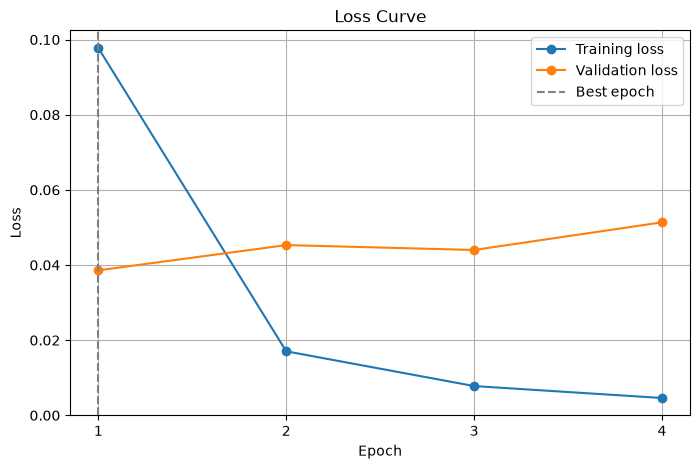

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history_df.index, history_df["loss"], marker="o", label="Training loss")
plt.plot(history_df.index, history_df["val_loss"], marker="o", label="Validation loss")
plt.axvline(x=history_df["val_loss"].idxmin(), color="gray", linestyle="--", label="Best epoch")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(history_df.index)
plt.legend()
plt.grid(True)
plt.show()

In [19]:
from sklearn.metrics import classification_report, roc_auc_score

y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)
y_true = y_test.values

print(classification_report(y_true, y_pred, target_names=["Legit", "Phishing"], digits=4))
print("Test AUC-ROC:", round(roc_auc_score(y_true, y_prob), 4))

97/97 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step
              precision    recall  f1-score   support

       Legit     0.9922    0.9786    0.9854      5885
    Phishing     0.9806    0.9930    0.9868      6427

    accuracy                         0.9861     12312
   macro avg     0.9864    0.9858    0.9861     12312
weighted avg     0.9862    0.9861    0.9861     12312

Test AUC-ROC: 0.9988


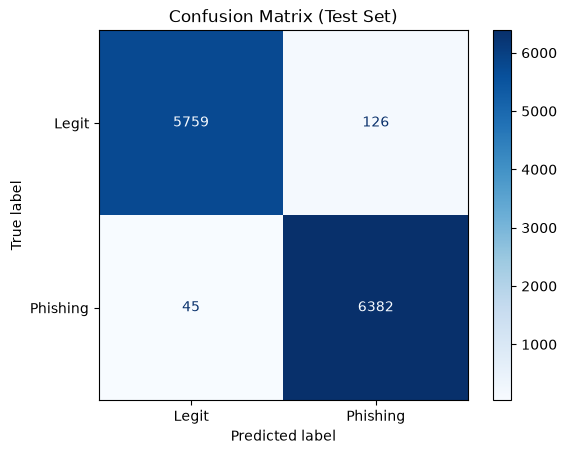

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["Legit", "Phishing"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (Test Set)")
plt.show()


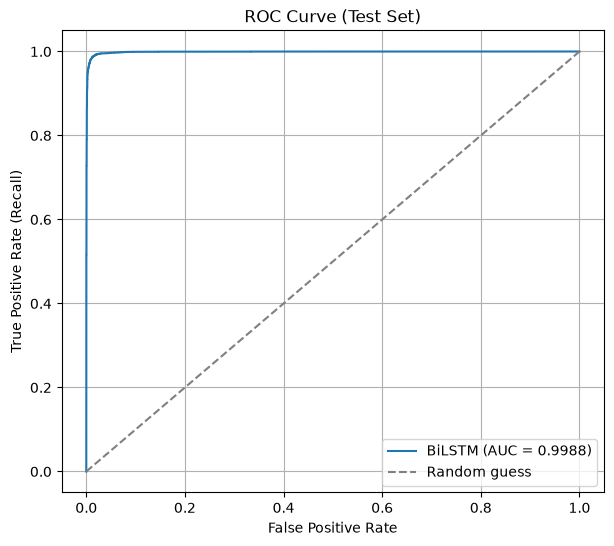

In [21]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_true, y_prob)
auc = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"BiLSTM (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.title("ROC Curve (Test Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.grid(True)
plt.show()

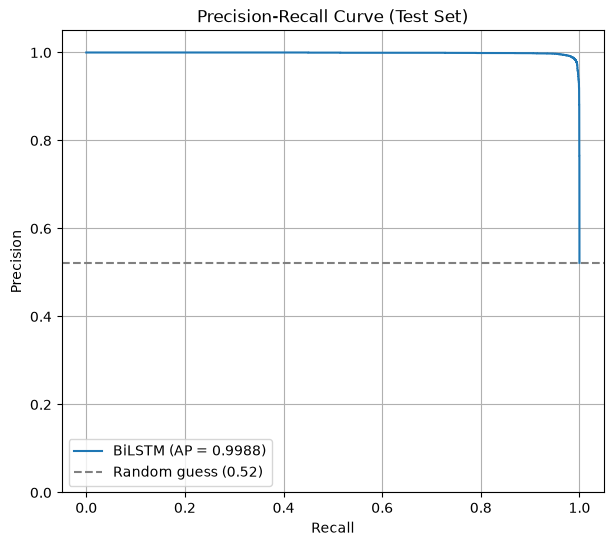

In [22]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)
baseline = y_true.mean()

plt.figure(figsize=(7, 6))
plt.plot(recall, precision, label=f"BiLSTM (AP = {ap:.4f})")
plt.axhline(y=baseline, linestyle="--", color="gray", label=f"Random guess ({baseline:.2f})")
plt.title("Precision-Recall Curve (Test Set)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

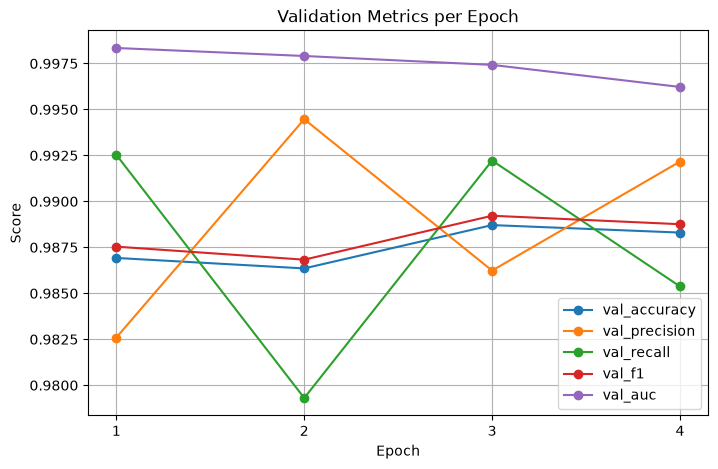

In [23]:
plt.figure(figsize=(8, 5))
for metric in ["val_accuracy", "val_precision", "val_recall", "val_f1", "val_auc"]:
    plt.plot(history_df.index, history_df[metric], marker="o", label=metric)
plt.title("Validation Metrics per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.xticks(history_df.index)
plt.legend()
plt.grid(True)
plt.show()

In [24]:
from lime.lime_text import LimeTextExplainer

explainer = LimeTextExplainer(class_names=["Legit", "Phishing"])

def predict_proba(texts):
    probs = model(tf.constant([[t] for t in texts]), training=False).numpy().ravel()
    return np.column_stack([1 - probs, probs])

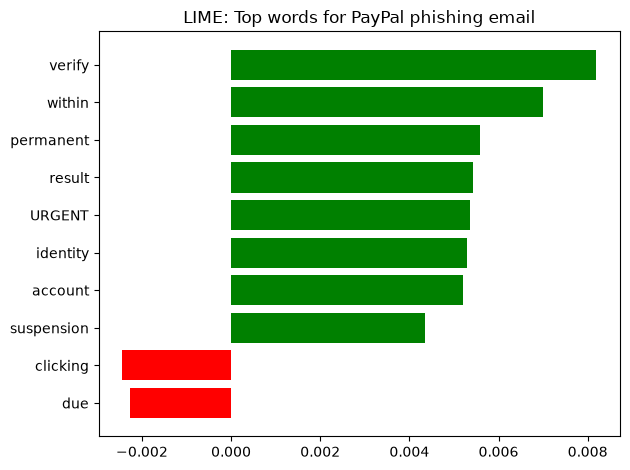

In [25]:
email = "URGENT: Your PayPal account has been limited due to suspicious activity. To restore full access, verify your identity within 24 hours by clicking the link below. Failure to do so will result in permanent suspension. http://paypal-secure-verify.com/login"

exp = explainer.explain_instance(email, predict_proba, num_features=10, num_samples=1000)

fig = exp.as_pyplot_figure()
plt.title("LIME: Top words for PayPal phishing email")
plt.tight_layout()
plt.show()

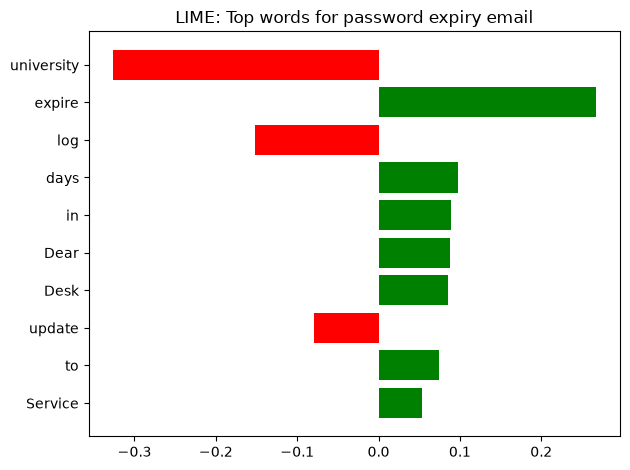

In [26]:
email = "Dear student, your university password will expire in 3 days. Please log in to the student portal to update it. IT Service Desk"

exp = explainer.explain_instance(email, predict_proba, num_features=10, num_samples=1000)

fig = exp.as_pyplot_figure()
plt.title("LIME: Top words for password expiry email")
plt.tight_layout()
plt.show()